# Session 3 lab: Clean it, check it, log it

<p class="lead">
Three files from three sources, each with its own problems: repeated football matches, a usage file with most of its dates missing, and a retail workbook whose sheets must be joined without losing or doubling anything.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/03_cleaning_and_preparing_lab.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

The head of analytics says:

> *"We have been handed three files for next quarter's reports. Before anyone builds a chart on them: what is wrong with each one, what did you fix, and can I see the proof?"*

Your job today is not to find insights. It is to make each file **fit for use**, show the evidence, and say clearly what still cannot be trusted.

> **About the data**
>
> - **World Cup results**: compiled for *Sports Viz Sundays 2018* and published in Tableau's sample-data catalog. We download it from that source for learning; we do not redistribute it, and the course does not claim a licence for it.
> - **Mobile OS usage**: from **Statcounter Global Stats** (licence CC BY-SA 3.0), via Tableau's sample-data catalog. Each percentage is a share of **page views** on the websites Statcounter tracks, not a share of devices sold or of people.
> - **Superstore**: Tableau's sample for a **fictitious** company. Sales and Profit are in source monetary units; no currency is stated.

---

## How this lab works

| Part | What you do | Tasks |
|---|---|---|
| **Guided practice** | Follow along step by step, everyone together | G1–G5 |
| **Independent tasks** | Same skills, new questions, on your own or in pairs | I1–I6 |
| **Challenge** | Harder reasoning and debugging | C1–C2 |

Each task has a level:

- **Core**: everyone completes it; it is enough for your portfolio.
- **Stretch**: for when you finish the core tasks early.
- **Challenge**: optional, harder reasoning.

---

## What you will be able to do

1. Profile a new file: size, types, missing values and duplicates.
2. Find exact duplicates and confirm the fix against an independent total.
3. Detect stray spaces, broken characters and inconsistent names.
4. Diagnose missing dates and choose a subset you can defend.
5. Join three tables with `validate=`, `indicator=True` and row-count checks.
6. Keep a **cleaning log** with before and after counts.

**Evidence you keep:** your cleaning log, the duplicate check against official totals, your Mobile OS decision with its reason, the Superstore join checks and your fix for the debugging challenge.

Before you start, work through the [Session 3 lecture](03_cleaning_and_preparing_lecture.md).

---

## Guided practice

### G1 (Core): Load the three files

The first cell is the course setup cell you know from Session 2: it downloads the Superstore workbook and checks it. The second cell defines `fetch`, which downloads a file into memory and checks its fingerprint, and then loads the other two files. Nothing is saved over the originals: every change today happens to a **copy** in Python.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
import hashlib
import io


def fetch(url, expected_sha256):
    """Download a file into memory and check its SHA-256 fingerprint."""
    with urllib.request.urlopen(url) as response:
        data = response.read()
    if hashlib.sha256(data).hexdigest() != expected_sha256:
        print("WARNING: this file has changed since the course was written:", url)
        print("Your numbers may differ from the lab. Ask your facilitator.")
    return data


world_cup_bytes = fetch(
    "https://public.tableau.com/app/sample-data/world_cup_results.xlsx",
    "dbad641c16c914c14fef0c95bf6f918fa5d2746671e4dc269b6a1ec3e2a3cc45",
)
mobile_bytes = fetch(
    "https://public.tableau.com/app/sample-data/mobile_os_usage.csv",
    "0db44110e84a31c06491af89a30949cd8ced1c42fac56488cb04ca4f9e449995",
)

matches_raw = pd.read_excel(io.BytesIO(world_cup_bytes), sheet_name="WorldCupMatches")
cups = pd.read_excel(io.BytesIO(world_cup_bytes), sheet_name="WorldCups")
mobile_raw = pd.read_csv(io.BytesIO(mobile_bytes))

print("World Cup matches:", matches_raw.shape)
print("World Cup tournaments:", cups.shape)
print("Mobile OS usage:", mobile_raw.shape)

World Cup matches: (852, 12)
World Cup tournaments: (20, 10)
Mobile OS usage: (1898, 3)


Start the cleaning log now. Every step you take today adds one row to it.

In [3]:
cleaning_log = []


def log_step(dataset, change, why, before, after):
    """Add one row to the cleaning log."""
    cleaning_log.append({"dataset": dataset, "change": change, "why": why,
                         "rows_before": before, "rows_after": after})


print("Cleaning log ready.")

Cleaning log ready.


---

### G2 (Core): Profile the match results

Before fixing anything, look. What does one row represent, what types are the columns, and is anything missing?

In [4]:
matches_raw.head()

,Year,Date,Time,Round,Stadium,City,Country,HomeTeam,HomeGoals,AwayGoals,AwayTeam,Observation
0,1930,1930-07-13,15:00,Group 1,Pocitos,Montevideo,Uruguay,France,4,1,Mexico,
1,1930,1930-07-13,15:00,Group 4,Parque Central,Montevideo,Uruguay,USA,3,0,Belgium,
2,1930,1930-07-14,12:45,Group 2,Parque Central,Montevideo,Uruguay,Yugoslavia,2,1,Brazil,
3,1930,1930-07-14,14:50,Group 3,Pocitos,Montevideo,Uruguay,Romania,3,1,Peru,
4,1930,1930-07-15,16:00,Group 1,Parque Central,Montevideo,Uruguay,Argentina,1,0,France,


In [5]:
print(matches_raw.dtypes)
print()
print("Missing values per column:")
print(matches_raw.isna().sum())

Year                    int64
Date           datetime64[ns]
Time                   object
Round                  object
Stadium                object
City                   object
Country                object
HomeTeam               object
HomeGoals               int64
AwayGoals               int64
AwayTeam               object
Observation            object
dtype: object

Missing values per column:
Year           0
Date           0
Time           0
Round          0
Stadium        0
City           0
Country        0
HomeTeam       0
HomeGoals      0
AwayGoals      0
AwayTeam       0
Observation    0
dtype: int64


One row is **one match**: a year, a date, two teams and their goals. The `Observation` column holds notes such as "win after extra time".

`isna()` reports no missing values at all, yet most matches have no note. Blanks can be stored as **empty text** instead of `NaN`, and then `isna()` cannot see them:

In [6]:
empty_notes = matches_raw["Observation"].astype(str).str.strip() == ""
print("Observation cells that are empty text:", empty_notes.sum(), "of", len(matches_raw))

Observation cells that are empty text: 787 of 852


Here an empty note is expected (most matches end normally), so we leave it. The lesson: check for empty text as well as `NaN` before you call a column complete.

The `WorldCups` sheet records the official number of matches and goals for each tournament. That gives us an **independent check**: count the match rows per year and compare.

In [7]:
check = pd.DataFrame({
    "match_rows": matches_raw.groupby("Year").size(),
    "official_matches": cups.set_index("Year")["MatchesPlayed"],
})
check["difference"] = check["match_rows"] - check["official_matches"]
check[check["difference"] != 0]

,match_rows,official_matches,difference
Year,,,
2014,80,64,16


> **Predict before you continue**
>
> Only one tournament disagrees, and it has **more** rows than matches played. Write down two possible explanations before you run G3.

---

### G3 (Core): Find and remove the duplicates

`duplicated()` marks rows that are identical, in every column, to an earlier row.

In [8]:
is_copy = matches_raw.duplicated()
print("Exact duplicate rows:", is_copy.sum())
print("Years affected:", matches_raw.loc[is_copy, "Year"].value_counts().to_dict())

Exact duplicate rows: 16
Years affected: {2014: 16}


Look at both copies of a few of them. `keep=False` marks the first copy too, so you can see the pairs side by side.

In [9]:
pairs = matches_raw[matches_raw.duplicated(keep=False)]
pairs.sort_values(["Date", "HomeTeam"])[["Year", "Date", "Round", "HomeTeam", "HomeGoals", "AwayGoals", "AwayTeam"]].head(6)

,Year,Date,Round,HomeTeam,HomeGoals,AwayGoals,AwayTeam
820,2014,2014-06-28,Round of 16,Brazil,1,1,Chile
836,2014,2014-06-28,Round of 16,Brazil,1,1,Chile
821,2014,2014-06-28,Round of 16,Colombia,2,0,Uruguay
837,2014,2014-06-28,Round of 16,Colombia,2,0,Uruguay
833,2014,2014-06-29,Round of 16,Costa Rica,1,1,Greece
839,2014,2014-06-29,Round of 16,Costa Rica,1,1,Greece


Same teams, same date, same score, same stadium: the same match recorded twice. Each match is one real event, so these are **true duplicates**. Remove them from a copy, log the step, and run the independent check again.

In [10]:
before = len(matches_raw)
matches = matches_raw.drop_duplicates().copy()
log_step("World Cup matches", "Removed exact duplicate rows",
         "Same match recorded twice; match count exceeded the official total", before, len(matches))

check["match_rows_clean"] = matches.groupby("Year").size()
print("Years where clean rows differ from the official count:",
      (check["match_rows_clean"] != check["official_matches"]).sum())

Years where clean rows differ from the official count: 0


> **Remember**
>
> The fix is confirmed by a number that came from **somewhere else** (the official match count), not just by "the duplicates are gone". Copy the before and after counts into your evidence log.

---

### G4 (Core): Text problems — spaces, broken characters, names

Text columns hide problems that are invisible when you look at a few rows. Start with stray spaces.

In [11]:
for column in ["City", "Stadium", "HomeTeam", "AwayTeam"]:
    text = matches[column].astype(str)
    print(f"{column:9} values with leading or trailing spaces: {(text != text.str.strip()).sum()}")

City      values with leading or trailing spaces: 836
Stadium   values with leading or trailing spaces: 0
HomeTeam  values with leading or trailing spaces: 0
AwayTeam  values with leading or trailing spaces: 0


Every `City` value ends with a space. That is harmless until you join on city or type `"Paris"` in a filter. Strip it and log it (a text fix does not change the row count, so before and after are the same).

In [12]:
matches["City"] = matches["City"].str.strip()
log_step("World Cup matches", "Stripped spaces from City", "Every City value ended in a space",
         len(matches), len(matches))
print("Cities with spaces left:", (matches["City"] != matches["City"].str.strip()).sum())

Cities with spaces left: 0


Next, **broken characters**. The symbols `ï¿½` are what is left of letters such as **ô** or **é** after the file passed through the wrong encoding. The original letter is gone.

In [13]:
text_columns = ["City", "Stadium", "HomeTeam", "AwayTeam"]
broken = matches[text_columns].apply(lambda column: column.astype(str).str.contains("ï¿½"))
print("Rows with a broken character:", broken.any(axis=1).sum())
pd.Series(pd.unique(matches[text_columns].where(broken).stack())).head(12)

Rows with a broken character: 73


0                                   Stade Vï¿½lodrome
1     Maracanï¿½ - Estï¿½dio Jornalista Mï¿½rio Filho
2                                             Malmï¿½
3                                        Norrkï¿½Ping
4                           Nou Camp - Estadio Leï¿½n
5                                        Dï¿½Sseldorf
6                      Estadio Josï¿½ Marï¿½a Minella
7                 Estadio Olï¿½mpico Chateau Carreras
8                     Estadio Municipal de Balaï¿½dos
9                                         La Coruï¿½A
10                   Estadio Olï¿½mpico Universitario
11                                    Cï¿½te d'Ivoire
dtype: object

Some of these are easy to read (`Cï¿½te d'Ivoire` is Côte d'Ivoire), others are not. We **flag** the affected rows rather than guessing; correcting them needs a trusted reference list.

In [14]:
matches["text_broken_flag"] = broken.any(axis=1).astype(int)
log_step("World Cup matches", "Flagged rows with broken characters (not corrected)",
         "Encoding damage; original letters cannot be recovered from the file", len(matches), len(matches))
matches["text_broken_flag"].value_counts()

text_broken_flag
0    763
1     73
Name: count, dtype: int64

Finally, **names**. Look for teams that might be the same country under two names.

In [15]:
teams = pd.concat([matches["HomeTeam"], matches["AwayTeam"]])
teams[teams.str.contains("Iran|Germany")].value_counts()

Germany FR    62
Germany       44
Iran           6
IR Iran        6
Name: count, dtype: int64

> **Not every difference is an error**
>
> - `Iran` and `IR Iran` are the **same** team written two ways: a candidate for a documented mapping.
> - `Germany FR` (West Germany), `German DR` (East Germany) and `Germany` are **historically different** teams. Merging them is an analytical choice, not a fix, and must be stated if you make it.
>
> You decide how to treat each one in I4.

---

### G5 (Core): Join the three Superstore sheets safely

The Superstore workbook has three sheets. Read them raw from the file the setup cell downloaded.

In [16]:
orders_raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
returns_raw = pd.read_excel(SOURCE_FILE, sheet_name="Returns")
people_raw = pd.read_excel(SOURCE_FILE, sheet_name="People")

print("Orders: ", orders_raw.shape)
print("Returns:", returns_raw.shape)
print("People: ", people_raw.shape)
people_raw

Orders:  (10194, 21)
Returns: (296, 2)
People:  (4, 2)


,Regional Manager,Region
0,Sadie Pawthorne,West
1,Chuck Magee,East
2,Roxanne Rodriguez,Central
3,Fred Suzuki,South


**Step 1: before the join, check the keys.** Orders will be joined to Returns on `Order ID` and to People on `Region`. Each key must be **unique** on the Returns and People side, or rows will multiply.

In [17]:
print("Returns: is Order ID unique?", returns_raw["Order ID"].is_unique)
print("People:  is Region unique?  ", people_raw["Region"].is_unique)
print("Returns: values in Returned:", returns_raw["Returned"].unique())

Returns: is Order ID unique? True
People:  is Region unique?   True
Returns: values in Returned: ['Yes']


**Step 2: join with `validate` and `indicator`.** Each order line has at most one returns row and exactly one region manager, so both joins are **many-to-one**.

In [18]:
step1 = orders_raw.merge(returns_raw, on="Order ID", how="left",
                         validate="many_to_one", indicator="returns_match")
step2 = step1.merge(people_raw, on="Region", how="left",
                    validate="many_to_one", indicator="people_match")

print("Rows: orders", len(orders_raw), "| after Returns", len(step1), "| after People", len(step2))
print()
print(step2["returns_match"].value_counts())
print()
print(step2["people_match"].value_counts())

Rows: orders 10194 | after Returns 10194 | after People 10194

returns_match
left_only     9394
both           800
right_only       0
Name: count, dtype: int64

people_match
both          10194
left_only         0
right_only        0
Name: count, dtype: int64


**Step 3: after the join, check a total and the unmatched rows.**

In [19]:
print("Sales before joins:", round(orders_raw["Sales"].sum(), 2))
print("Sales after joins: ", round(step2["Sales"].sum(), 2))
print("Lines without a manager:", step2["Regional Manager"].isna().sum())
print("Listed orders found in Orders:", returns_raw["Order ID"].isin(orders_raw["Order ID"]).sum(),
      "of", len(returns_raw))

Sales before joins: 2326534.35
Sales after joins:  2326534.35
Lines without a manager: 0
Listed orders found in Orders: 296 of 296


Read the output above:

- The row count and the Sales total did not change, so neither join multiplied anything.
- Lines whose order is **not** on the returns list get a blank `Returned`. Blank here means "not listed", not "unknown": that is why `load_orders()` turns it into a 0/1 flag.
- Every line found a manager.

Turn the blank into an explicit flag, and log the join.

In [20]:
orders_joined = step2.drop(columns=["returns_match", "people_match"])
orders_joined["returned_listed"] = orders_joined["Returned"].eq("Yes").astype(int)

log_step("Superstore", "Left-joined Returns (on Order ID) and People (on Region)",
         "Add returns listing and regional manager to each line; validated many-to-one",
         len(orders_raw), len(orders_joined))
orders_joined[["Order ID", "Region", "Regional Manager", "Returned", "returned_listed"]].head()

,Order ID,Region,Regional Manager,Returned,returned_listed
0,US-2023-103800,Central,Roxanne Rodriguez,NaN,0
1,US-2023-112326,Central,Roxanne Rodriguez,NaN,0
2,US-2023-112326,Central,Roxanne Rodriguez,NaN,0
3,US-2023-112326,Central,Roxanne Rodriguez,NaN,0
4,US-2023-141817,East,Chuck Magee,NaN,0


---

## Independent tasks

### I1 (Core): Profile the Mobile OS file

The file has three columns: a month, an operating system and its percentage of page views. Profile it the same way you profiled the matches.

In [21]:
print(mobile_raw.dtypes)
print()
print("Missing values per column:")
print(mobile_raw.isna().sum())
mobile_raw.head()

Date                        object
Mobile Operating System     object
Percent of Usage           float64
dtype: object

Missing values per column:
Date                       1772
Mobile Operating System       0
Percent of Usage              0
dtype: int64


,Date,Mobile Operating System,Percent of Usage
0,2008-12-01,Android,0.00
1,2008-12-01,iOS,32.56
2,2008-12-01,SymbianOS,42.02
3,2008-12-01,Series 40,0.00
4,2008-12-01,BlackBerry OS,0.00


Most dates are missing. Which months **do** have dates, how many operating systems does each have, and do their percentages add up to about 100?

In [22]:
dated = mobile_raw.dropna(subset=["Date"])
dated.groupby("Date").agg(
    systems=("Mobile Operating System", "nunique"),
    percent_total=("Percent of Usage", "sum"),
)

,systems,percent_total
Date,,
2008-12-01,26,100.00
2009-01-01,26,100.00
2009-02-01,26,100.01
2009-03-01,26,99.99
2009-04-01,22,99.17


Record in your evidence log:

1. How many rows have a date, and how many do not.
2. Which months are dated, and which of them look **complete** (all systems present, total close to 100).
3. One month that looks **incomplete**, and how you can tell.

### I2 (Core): Choose a subset you can defend

The undated rows cannot be placed in time. It is tempting to give them dates based on their **position** in the file, but row order is not evidence: a file can be sorted, filtered or appended in any order.

The defensible choice is to keep **only the dated rows**, and to mark the month that is incomplete.

In [23]:
before = len(mobile_raw)
mobile = mobile_raw.dropna(subset=["Date"]).copy()
mobile["Date"] = pd.to_datetime(mobile["Date"])

month_totals = mobile.groupby("Date")["Percent of Usage"].sum()
complete_months = month_totals[(month_totals - 100).abs() < 0.5].index
mobile["complete_month"] = mobile["Date"].isin(complete_months).astype(int)

log_step("Mobile OS", "Kept only rows with a date; flagged incomplete months",
         "Undated rows cannot be placed in time; row order is not evidence", before, len(mobile))
mobile.groupby("Date")["complete_month"].first()

Date
2008-12-01    1
2009-01-01    1
2009-02-01    1
2009-03-01    1
2009-04-01    0
Name: complete_month, dtype: int64

> **Your turn:** change the code in the next cell and run it again.

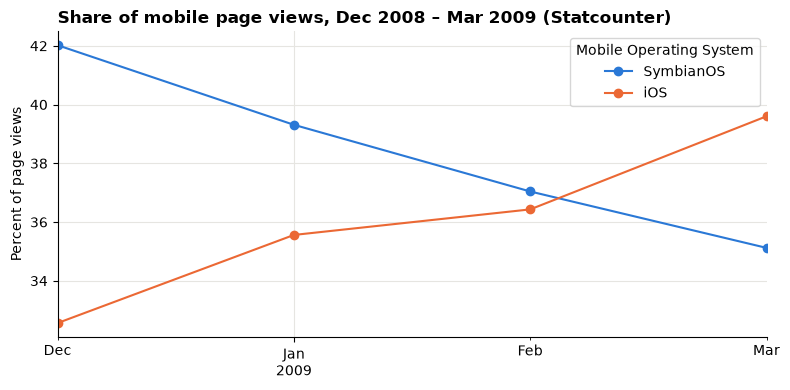

In [24]:
# 1. Run the cell: it charts the share of page views for two systems, complete months only.
# 2. Change the list to two or three other systems, for example "BlackBerry OS" or "Android".
# 3. Rewrite the title so it says exactly what the chart shows, including the period.
selected = ["iOS", "SymbianOS"]

subset = mobile[(mobile["complete_month"] == 1) & mobile["Mobile Operating System"].isin(selected)]
chart = subset.pivot(index="Date", columns="Mobile Operating System", values="Percent of Usage")
ax = chart.plot(marker="o", title="Share of mobile page views, Dec 2008 – Mar 2009 (Statcounter)")
ax.set_xlabel("")
ax.set_ylabel("Percent of page views")
plt.tight_layout()
plt.show()

Write one sentence describing your chart and one sentence on what the file **cannot** tell you (think about what a page-view share measures, and about the period covered).

---

### I3 (Core): How much did the duplicates matter?

Compare goals per match for each tournament using the **raw** and the **clean** match tables.

> **Your turn:** change the code in the next cell and run it again.

In [25]:
# 1. Run the cell and find the tournament where raw and clean differ.
# 2. Change "goals_per_match" to "matches" to compare match counts instead.
# 3. Then compare the clean goals with the official GoalsScored column in cups.
def per_tournament(table):
    goals = table["HomeGoals"] + table["AwayGoals"]
    return pd.DataFrame({
        "matches": table.groupby("Year").size(),
        "goals": goals.groupby(table["Year"]).sum(),
    }).assign(goals_per_match=lambda t: t["goals"] / t["matches"])


comparison = pd.DataFrame({
    "raw": per_tournament(matches_raw)["goals_per_match"],
    "clean": per_tournament(matches)["goals_per_match"],
})
comparison.tail(5)

,raw,clean
Year,,
1998,2.67,2.67
2002,2.52,2.52
2006,2.30,2.30
2010,2.27,2.27
2014,2.58,2.67


Did the duplicates change the **average** much? Would they have changed a **total** (all goals scored in 2014) more or less? Write your answer, with the numbers, in your log.

---

### I4 (Core): Finish the cleaning log

Decide how to treat `Iran` / `IR Iran` and the German teams from G4. Add one row to the log for your decision, even if the decision is "leave unchanged".

> **Your turn:** change the code in the next cell and run it again.

In [26]:
# 1. Edit the mapping: add or remove names you decide to combine.
# 2. Fill in the reason in log_step. If you change nothing, log that decision too.
name_map = {"IR Iran": "Iran"}

before_names = pd.concat([matches["HomeTeam"], matches["AwayTeam"]]).nunique()
matches["HomeTeam"] = matches["HomeTeam"].replace(name_map)
matches["AwayTeam"] = matches["AwayTeam"].replace(name_map)
after_names = pd.concat([matches["HomeTeam"], matches["AwayTeam"]]).nunique()

log_step("World Cup matches", f"Renamed teams: {name_map}", "Write your reason here",
         len(matches), len(matches))
print("Different team names before:", before_names, "| after:", after_names)

Different team names before: 83 | after: 82


Now print the whole log. This table is your main evidence for today.

In [27]:
pd.DataFrame(cleaning_log)

,dataset,change,why,rows_before,rows_after
0,World Cup matches,Removed exact duplicate rows,Same match recorded twice; match count exceede...,852,836
1,World Cup matches,Stripped spaces from City,Every City value ended in a space,836,836
2,World Cup matches,Flagged rows with broken characters (not corre...,Encoding damage; original letters cannot be re...,836,836
3,Superstore,Left-joined Returns (on Order ID) and People (...,Add returns listing and regional manager to ea...,10194,10194
4,Mobile OS,Kept only rows with a date; flagged incomplete...,Undated rows cannot be placed in time; row ord...,1898,126
5,World Cup matches,Renamed teams: {'IR Iran': 'Iran'},Write your reason here,836,836


---

### I5 (Stretch): Reshape the Mobile OS data

Make a **wide** table with one row per operating system and one column per month, then check each month's total and melt it back to long.

> **Your turn:** change the code in the next cell and run it again.

In [28]:
# 1. Run the cell. Which month's column does not add up to about 100?
# 2. Change sort_values("2008-12-01") to sort by another month.
wide = mobile.pivot(index="Mobile Operating System", columns="Date", values="Percent of Usage")
wide.columns = wide.columns.strftime("%Y-%m-%d")

print("Column totals:")
print(wide.sum().round(2))
wide.sort_values("2008-12-01", ascending=False).head(8)

Column totals:
Date
2008-12-01   100.00
2009-01-01   100.00
2009-02-01   100.01
2009-03-01    99.99
2009-04-01    99.17
dtype: float64


Date,2008-12-01,2009-01-01,2009-02-01,2009-03-01,2009-04-01
Mobile Operating System,,,,,
SymbianOS,42.02,39.31,37.04,35.12,34.25
iOS,32.56,35.56,36.43,39.60,41.91
Unknown,16.00,14.73,11.87,11.29,10.20
Playstation,4.47,4.33,3.58,3.18,2.85
WinCE,2.22,2.10,1.94,1.70,1.55
Linux,1.66,1.24,0.00,0.00,0.00
Other,1.07,1.12,1.52,0.95,NaN
Android,0.00,0.66,2.06,2.18,2.02


In [29]:
long_again = wide.reset_index().melt(id_vars="Mobile Operating System", var_name="Date",
                                     value_name="Percent of Usage").dropna()
print("Rows in mobile:", len(mobile), "| rows after reshaping back:", len(long_again))

Rows in mobile: 126 | rows after reshaping back: 126


Explain why some cells in the wide table are blank, and why we drop them (instead of filling them with 0) when melting back.

---

### I6 (Stretch): Which listed returns fall in the course period?

The Returns sheet lists orders from every year in the Orders sheet. Our course period is orders placed **2023 to 2025**. How many listed orders fall inside it?

> **Your turn:** change the code in the next cell and run it again.

In [30]:
# 1. Run the cell.
# 2. Change the period to only 2025 ("2025-01-01" to "2026-01-01") and run again.
start, end = "2023-01-01", "2026-01-01"

order_dates = orders_raw.groupby("Order ID")["Order Date"].min()
listed_dates = order_dates.reindex(returns_raw["Order ID"])
in_period = (listed_dates >= start) & (listed_dates < end)

print("Orders on the returns list:", len(returns_raw))
print("Of those, placed in the period:", in_period.sum())

Orders on the returns list: 296
Of those, placed in the period: 191


Compare your result with the number of distinct listed orders in `load_orders()` (Session 2, task G6). Do they agree?

---

## Challenge

### C1 (Challenge): The sales total that grew

A colleague adds regional **sales targets** to the order lines and reports total Sales from the joined table. Their total is bigger than yours.

> **Your turn:** change the code in the next cell and run it again.

In [31]:
# The colleague's code. It runs without errors, but the total is wrong.
# 1. Find out why the joined table has more rows than orders_raw.
# 2. Fix the targets table or the join so every order line appears exactly once.
# 3. Add validate= so the same mistake can never pass silently again.
targets = pd.DataFrame({
    "Region": ["West", "West", "East", "Central", "South"],
    "version": ["original", "revised", "original", "original", "original"],
    "target": [700_000, 760_000, 650_000, 500_000, 400_000],
})

with_targets = orders_raw.merge(targets, on="Region", how="left")
print("Rows:", len(orders_raw), "->", len(with_targets))
print("Total Sales reported by the colleague:", round(with_targets["Sales"].sum(), 2))
print("Total Sales in the Orders sheet:      ", round(orders_raw["Sales"].sum(), 2))

Rows: 10194 -> 13447
Total Sales reported by the colleague: 3066347.96
Total Sales in the Orders sheet:       2326534.35


> **How would you check your fix?**
>
> Your fixed join must keep the row count and the Sales total of `orders_raw`. Write a two-sentence message to the colleague that explains the mistake without blaming anyone, and names the check that would have caught it.

---

### C2 (Challenge): The tempting fill

Look at the rows straight after the last dated April 2009 row.

In [32]:
mobile_raw.iloc[118:132]

,Date,Mobile Operating System,Percent of Usage
118,2009-04-01,WinCE,1.55
119,2009-04-01,Nintendo 3DS,0.00
120,2009-04-01,Nintendo,0.00
121,2009-04-01,webOS,0.00
122,2009-04-01,WinXP,0.00
123,2009-04-01,Brew,0.00
124,2009-04-01,Motorola,0.00
125,2009-04-01,Win7,0.00
126,NaN,MeeGo,0.00
127,NaN,Maemo 5,0.00


April has fewer systems than the other months, and its total is below 100. The four undated rows that follow look like exactly the missing systems, and adding them brings April close to 100. A colleague proposes filling every blank date with the date of the row above it.

In your log, answer:

1. What evidence supports giving those four rows the April date? What evidence is missing?
2. What would forward-filling do to the other undated rows, and why is that far more dangerous?
3. What would you need from the data provider to use the undated rows at all?

---

## Exit ticket

1. One duplicate you removed and the independent number that confirmed the fix.
2. Your Mobile OS decision in one sentence, with its reason.
3. The three checks you ran around the Superstore join.
4. Why the colleague's total in C1 grew.
5. One thing you are still unsure about.

## Evidence to keep

- [ ] Duplicate check against the official match counts, before and after (G2–G3)
- [ ] Text problems found and how each was treated: fixed, flagged or left (G4, I4)
- [ ] Superstore join with key checks, `validate`, `indicator`, row counts and Sales total (G5)
- [ ] Mobile OS profile and your defended subset (I1–I2)
- [ ] Your complete cleaning log (I4)
- [ ] Your fix and message for the debugging challenge (C1), if attempted

## After the lab

- Previous: [Session 3 lecture](03_cleaning_and_preparing_lecture.md). Next: [Session 4 lecture](04_descriptive_statistics_lecture.md), descriptive statistics and distributions.